#imports

In [1]:
import pandas as pd; import numpy as np ; import matplotlib.pyplot as plt ; import seaborn as sns;
from numpy import argmax;
import scipy.stats as st;

from sklearn.datasets import make_classification as mc;
from sklearn.datasets import make_regression as mr
from sklearn.datasets import load_iris;
from sklearn.datasets import load_diabetes
from sklearn.datasets import load_breast_cancer
from sklearn.datasets import fetch_openml

from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report;
from sklearn.metrics import roc_auc_score;
from sklearn.metrics import precision_score;
from sklearn.metrics import recall_score;
from sklearn.metrics import get_scorer_names
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error as MSE

from sklearn.linear_model import LogisticRegression as LR;
from sklearn.linear_model import LinearRegression as LinReg;
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import SGDClassifier as SGDC;

from sklearn.model_selection import train_test_split;
from sklearn.model_selection import cross_validate;
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold;
from sklearn.model_selection import LearningCurveDisplay
from sklearn.model_selection import RandomizedSearchCV as RSCV;
from sklearn.model_selection import LeavePOut;
from sklearn.model_selection import GridSearchCV as GSCV;

from sklearn.feature_selection import RFE
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
from sklearn.feature_selection import f_regression
from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import f_classif
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectFromModel

from sklearn.neighbors import KNeighborsRegressor as KNNR
from sklearn.neighbors import KNeighborsClassifier as KNNC

from sklearn.gaussian_process import GaussianProcessClassifier as GPC
from sklearn.gaussian_process.kernels import RBF

from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.preprocessing import StandardScaler as SC;
from sklearn.preprocessing import label_binarize
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier as RFC;
from sklearn.ensemble import RandomForestRegressor as RFR;
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.ensemble import ExtraTreesClassifier as ETC;
from sklearn.ensemble import ExtraTreesRegressor as ETR;
from sklearn.ensemble import AdaBoostClassifier as AdaBoost;
from sklearn.ensemble import AdaBoostRegressor;
from sklearn.ensemble import GradientBoostingRegressor as GBR;

from sklearn.tree import DecisionTreeClassifier as DTC;
from sklearn.tree import DecisionTreeRegressor  as DTR
from sklearn.tree import plot_tree

from sklearn.naive_bayes import GaussianNB as GNB;

from sklearn.svm import SVC;
from sklearn.svm import SVR;

from sklearn.neural_network import MLPClassifier as MLPC
from sklearn.neural_network import MLPRegressor as MLPR;

from sklearn.utils.class_weight import compute_class_weight

from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import ADASYN
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import BorderlineSMOTE

from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import NearMiss
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import EditedNearestNeighbours


from yellowbrick.classifier import ROCAUC;
from yellowbrick.classifier import PrecisionRecallCurve;

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA;

from yellowbrick.model_selection import LearningCurve

from sklearn.pipeline import make_pipeline;

from tqdm.notebook import tqdm

import warnings;warnings.simplefilter("ignore")

# 1.Постройте по получившемуся набору данных простую модель машинного обучения и оцените ее эффективность.

In [15]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
sex = pd.get_dummies(training_set['Sex'], drop_first=True)
embark = pd.get_dummies(training_set['Embarked'], drop_first=True)
training_set = pd.concat([training_set, sex, embark], axis=1)
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)
y = training_set[['Survived']]
x = training_set.drop(['Survived'],axis=1)
x_tr,x_val,y_tr,y_val = train_test_split(x,y,train_size=0.8)

m=LR();m.fit(x_tr,y_tr);print(f'Accuracy модели логистической регрессии равен: {m.score(x_val,y_val)}')

Precision модели логистической регрессии равен: 0.8041958041958042


# 2.Ответьте на следующие вопросы при помощи визуализации и численных данных по исходному набору данных:

# 3.Какова доля выживших после крушения пассажиров? Какова доля мужчин и женщин среди выживших?

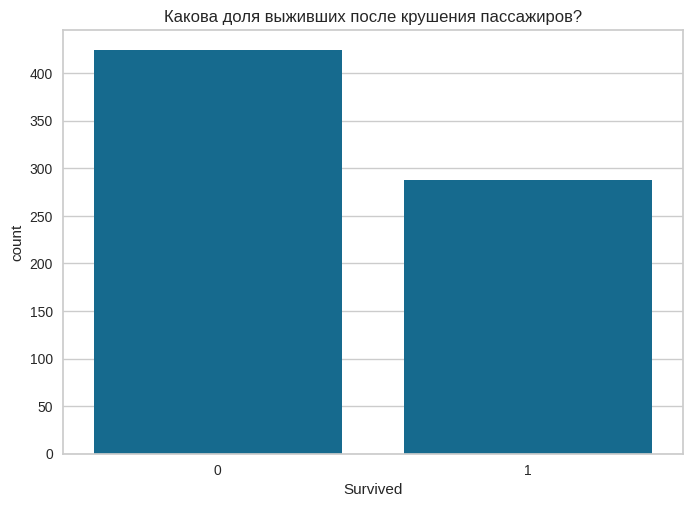

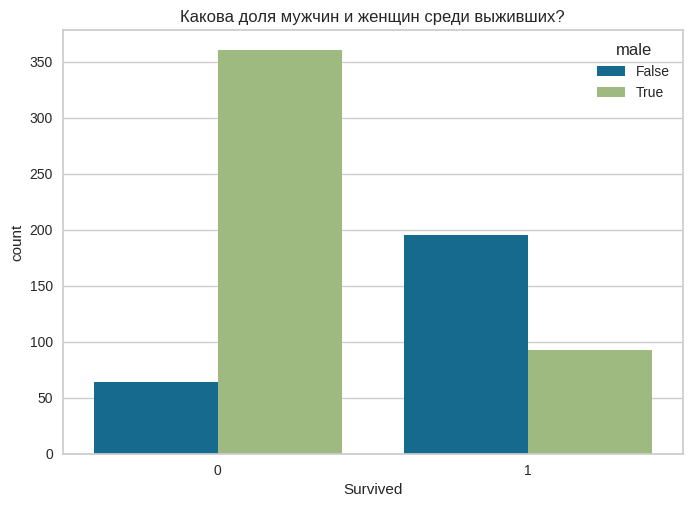

In [24]:
#Какова доля выживших после крушения пассажиров?
sns.countplot(x='Survived', data=training_set).set(title='Какова доля выживших после крушения пассажиров?');plt.show()

#Какова доля мужчин и женщин среди выживших?
sns.countplot(x='Survived', data=training_set, hue='male').set(title='Какова доля мужчин и женщин среди выживших?');plt.show()

# 4.Сколько пассажиров ехало в каждом классе? Кого было больше в самом многолюдном классе — мужчин или женщин?

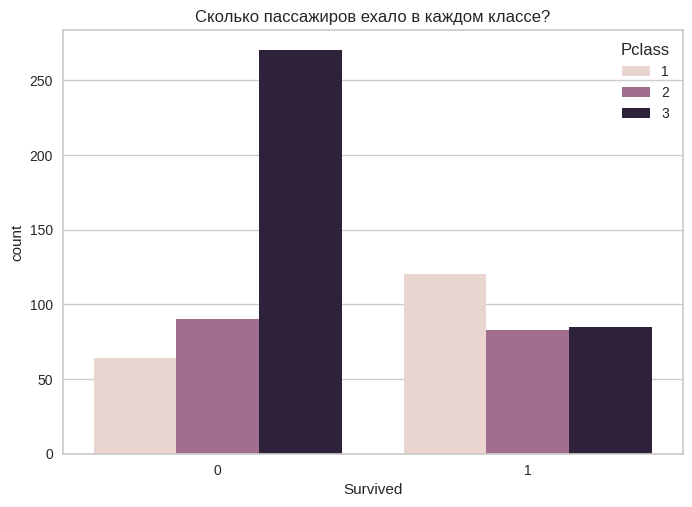

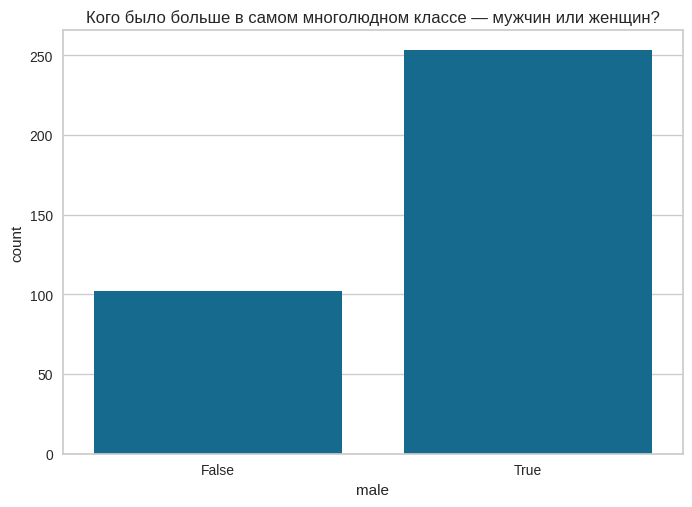

In [33]:
sns.countplot(x='Survived', data=training_set, hue='Pclass').set(title='Сколько пассажиров ехало в каждом классе?');plt.show()

sns.countplot(x='male',data=training_set[training_set['Pclass']==3]).set(title='Кого было больше в самом многолюдном классе — мужчин или женщин?');plt.show()

# 5.Все ли признаки несут в себе полезную информацию? Почему? Избавьтесь от ненужных столбцов.

In [ ]:
#Все ли признаки несут в себе полезную информацию? Почему?
'''
Нет, не все.
Номера билетов, ID пассажиров уникальны и не несут важной информации.
Так же Cabin из-за большого количества пропусков не несёт достаточного количества информации,
его можно сбросить для уменьшения количества признаков и избежать проклятия размерности.
'''

training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)

# 6.Посчитайте, насколько сильно коррелируют друг с другом цена за билет и возраст пассажиров. Также проверьте наличие этой зависимости визуально (в этом вам поможет построение диаграммы рассеяния).

In [34]:
training_set.columns

Index(['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'male', 'Q',
       'S'],
      dtype='object')

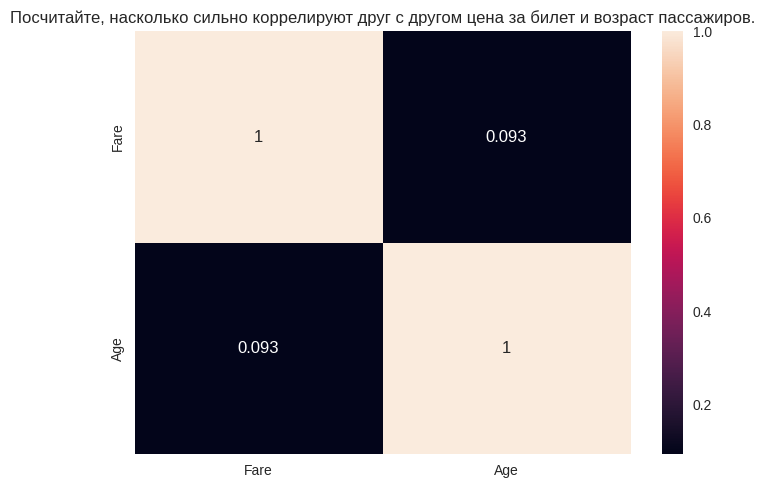

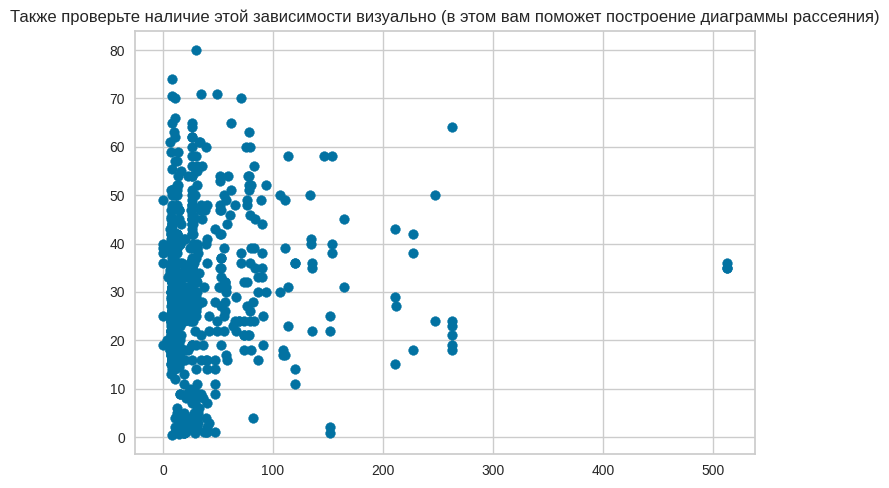

In [44]:
sns.heatmap(training_set[['Fare', 'Age']].corr(),annot=True).set(title='Посчитайте, насколько сильно коррелируют друг с другом цена за билет и возраст пассажиров.');plt.show()

plt.scatter(training_set[['Fare']],training_set[['Age']]);plt.title('Также проверьте наличие этой зависимости визуально (в этом вам поможет построение диаграммы рассеяния)');plt.show();


# 7.Правда ли, что чаще выживали пассажиры с более дорогими билетами? А есть ли зависимость выживаемости от класса?

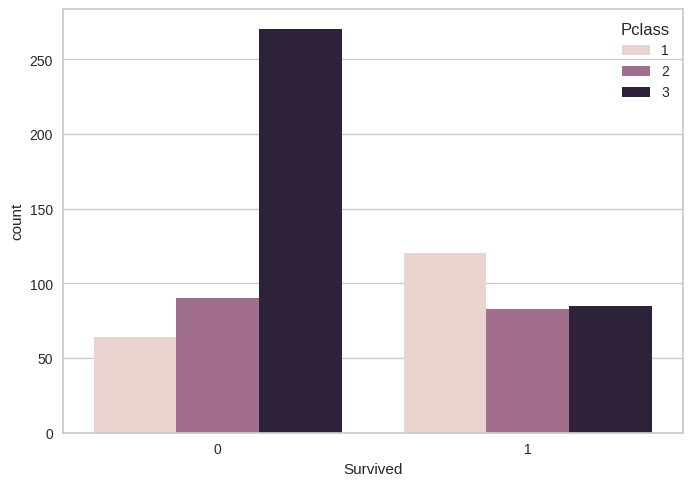





Частота выживших в классе 1 равна 0.6521739130434783
Частота выживших в классе 2 равна 0.4797687861271676
Частота выживших в классе 3 равна 0.23943661971830985






In [53]:
sns.countplot(x = 'Survived', data = training_set,hue='Pclass');plt.show()

print(f'\n\n\n')
f = lambda x: f'Частота выживших в классе {x} равна {training_set[training_set["Pclass"]==x]["Survived"].sum()/training_set[training_set["Pclass"]==x].shape[0]}'
print(f(1))
print(f(2))
print(f(3))
print(f'\n\n\n')

# 8.Какова связь между стоимостью билета и портом отправления? Выведите минимальную, среднюю и максимальную сумму, которую заплатили пассажиры за проезд. Проделайте то же самое только для тех пассажиров, которые сели на корабль в Саутгемптоне.

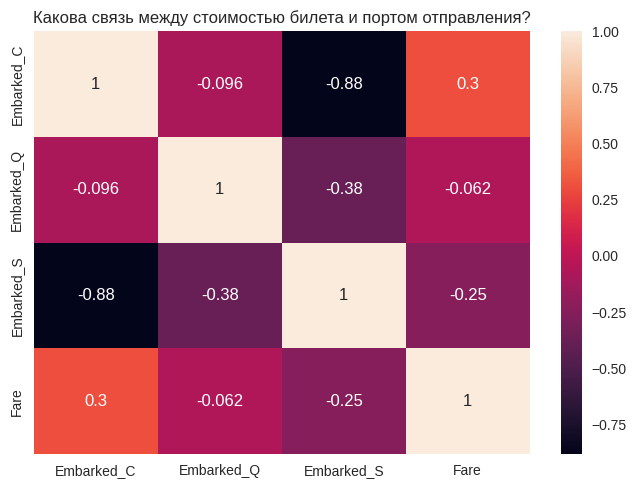

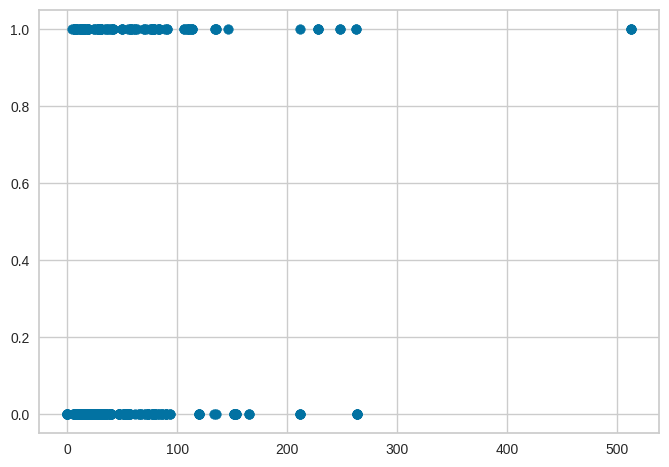

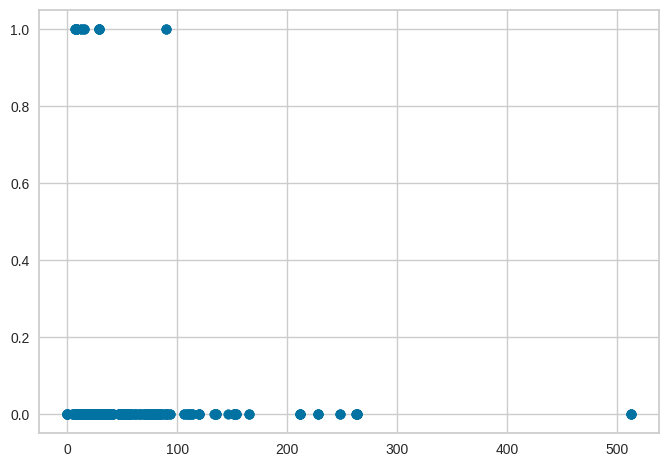

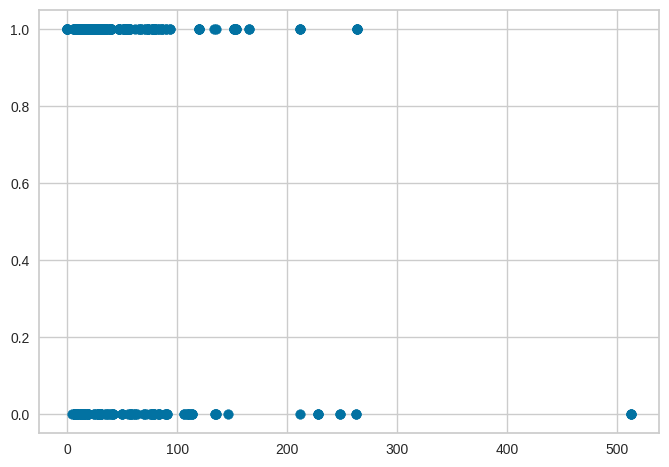





#Выведите минимальную, среднюю и максимальную сумму, которую заплатили пассажиры за проезд. 


,Fare
count,712.000000
mean,34.567251
std,52.938648
min,0.000000
25%,8.050000
50%,15.645850
75%,33.000000
max,512.329200






# Проделайте то же самое только для тех пассажиров, которые сели на корабль в Саутгемптоне.


,Fare
count,554.000000
mean,27.476284
std,36.546362
min,0.000000
25%,8.050000
50%,13.000000
75%,27.862500
max,263.000000


In [73]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
training_set = pd.get_dummies(training_set, columns=['Embarked'], prefix='Embarked')

#Какова связь между стоимостью билета и портом отправления?
sns.heatmap(training_set[['Embarked_C','Embarked_Q','Embarked_S', 'Fare']].corr(),annot=True).set(title='Какова связь между стоимостью билета и портом отправления?');plt.show()
plt.scatter(training_set[['Fare']],training_set[['Embarked_C']]);plt.show();
plt.scatter(training_set[['Fare']],training_set[['Embarked_Q']]);plt.show();
plt.scatter(training_set[['Fare']],training_set[['Embarked_S']]);plt.show();

print(f'\n\n\n')
print(f'#Выведите минимальную, среднюю и максимальную сумму, которую заплатили пассажиры за проезд. ')
#Выведите минимальную, среднюю и максимальную сумму, которую заплатили пассажиры за проезд.
display(training_set[['Fare']].describe())

print(f'\n\n\n')
print(f'# Проделайте то же самое только для тех пассажиров, которые сели на корабль в Саутгемптоне.')
# Проделайте то же самое только для тех пассажиров, которые сели на корабль в Саутгемптоне.
display(training_set[['Fare']][training_set['Embarked_S']==True].describe())

# 9.Выведите гистограммы, показывающие распределения стоимостей билетов в зависимости от места посадки.

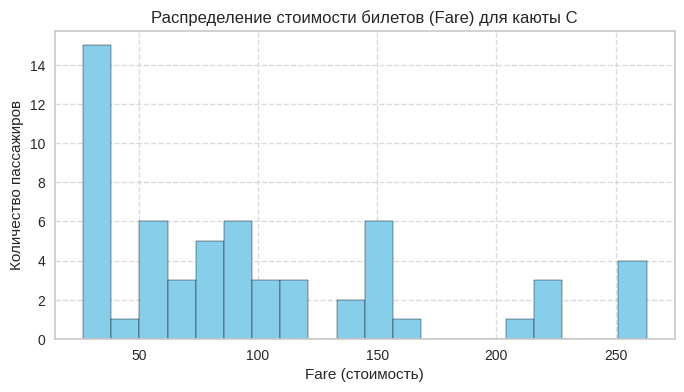

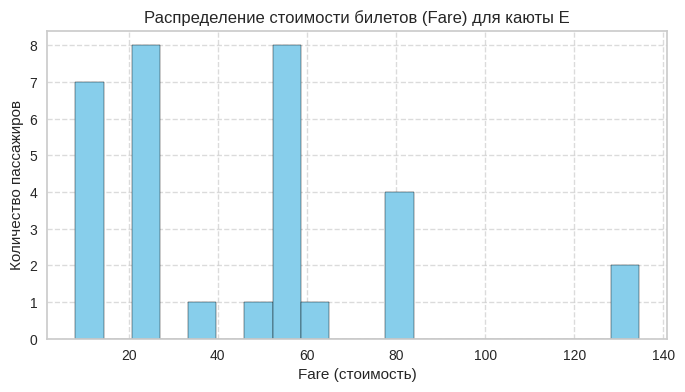

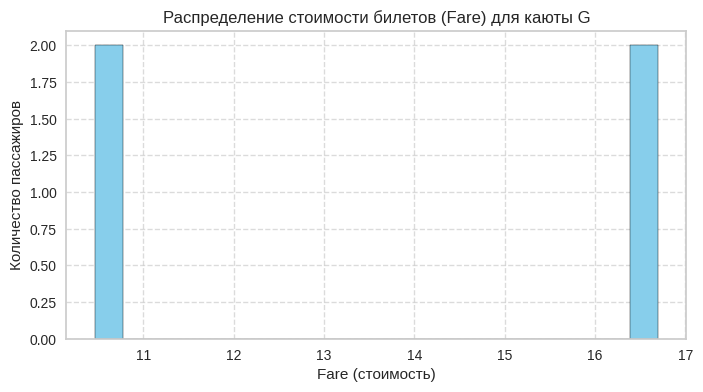

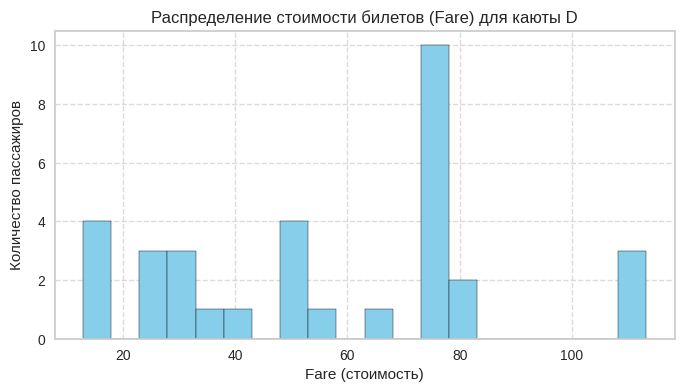

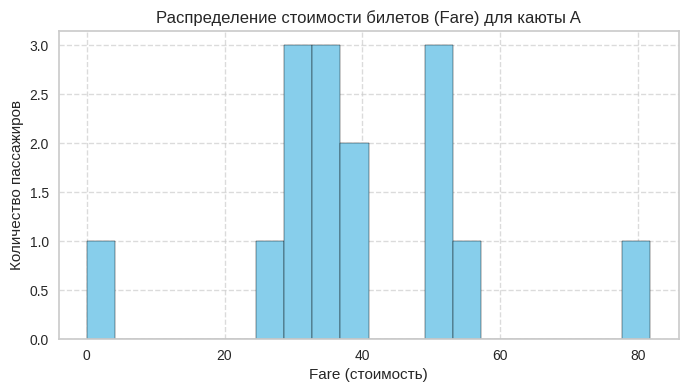

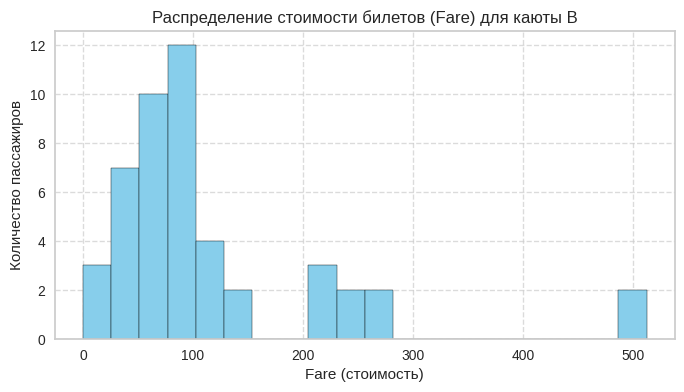

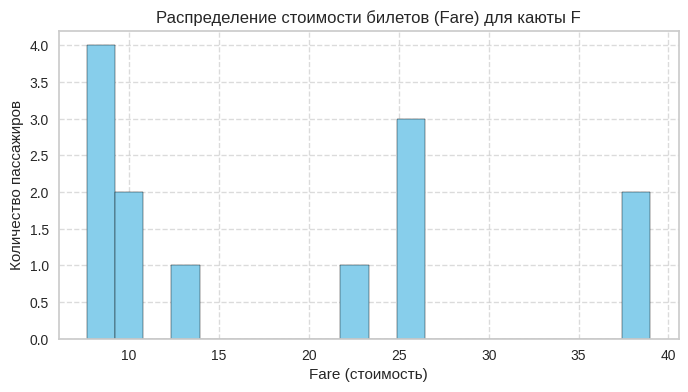

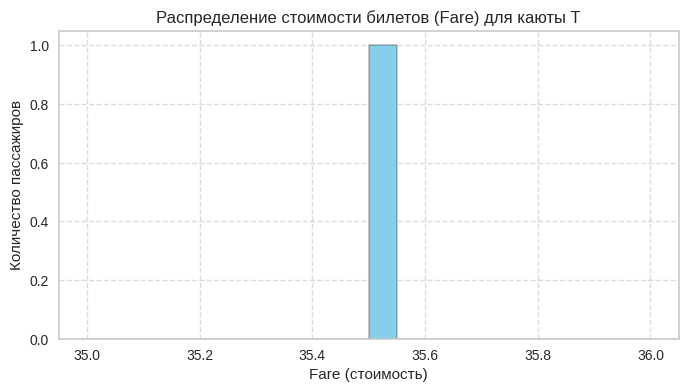

In [89]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
tr = training_set[ training_set['Cabin'].notna() ]
tr['Cabin_sym'] = tr['Cabin'].str[0]

for cabin in tr['Cabin_sym'].unique():
    plt.figure(figsize=(8, 4))
    plt.hist(tr['Fare'][tr['Cabin_sym'] == cabin], bins=20, color='skyblue', edgecolor='black')
    plt.title(f'Распределение стоимости билетов (Fare) для каюты {cabin}')
    plt.xlabel('Fare (стоимость)')
    plt.ylabel('Количество пассажиров')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()


# 10.Оцените репрезентативность представленной выборки. Сколько всего было пассажиров Титаника? Сколько из них выжило? Какую долю составляет представленный набор данных от всей генеральной совокупности?

In [93]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
print(f'Сколько всего было пассажиров Титаника? - {training_set.shape[0]}')

print(f'Сколько из них выжило? - {training_set["Survived"].sum()}')

print(f'Какую долю составляет представленный набор данных от всей генеральной совокупности? - {training_set["Survived"].sum()/training_set.shape[0]}')

Сколько всего было пассажиров Титаника? - 891
Сколько из них выжило? - 342
Какую долю составляет представленный набор данных от всей генеральной совокупности? - 0.3838383838383838


# 11.Разделите выборку на тестовую и обучающую части при помощи train_test_split(). Изобразите на графиках распределение некоторых атрибутов и целевой переменной. Насколько однородно получившееся разбиение?

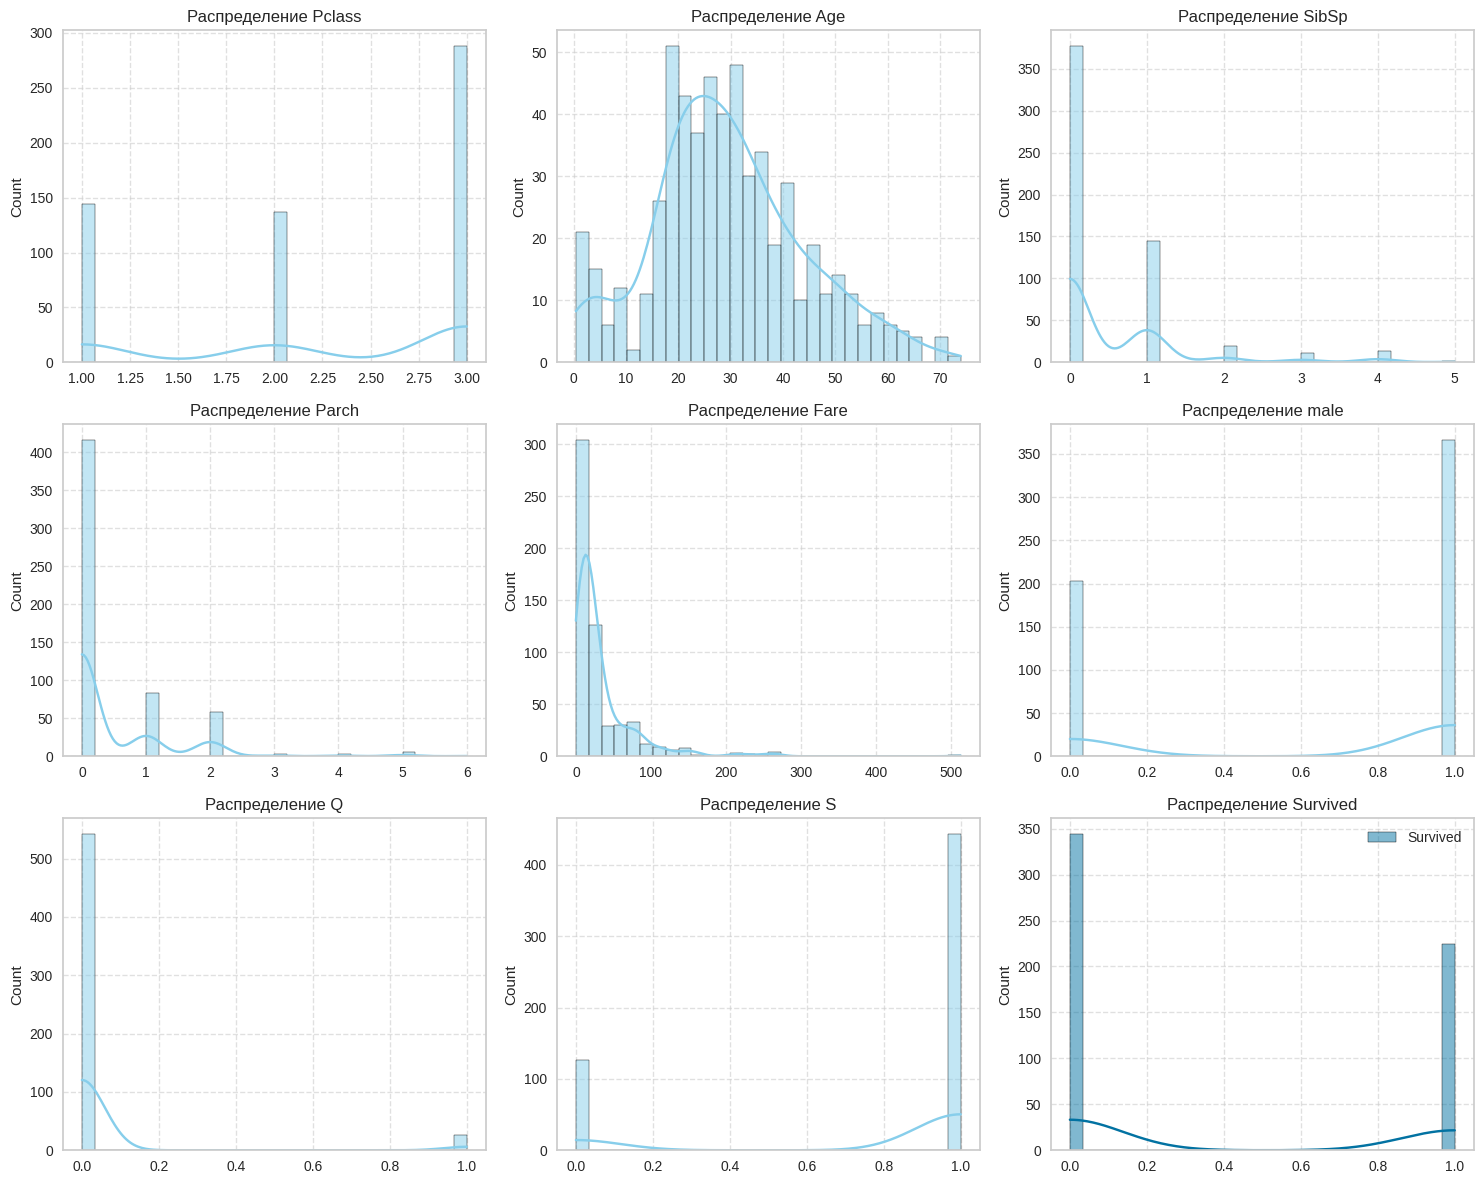

In [7]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
sex = pd.get_dummies(training_set['Sex'], drop_first=True)
embark = pd.get_dummies(training_set['Embarked'], drop_first=True)
training_set = pd.concat([training_set, sex, embark], axis=1)
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)
y = training_set[['Survived']]
x = training_set.drop(['Survived'],axis=1)

#Разделите выборку на тестовую и обучающую части при помощи train_test_split()
x_tr,x_val,y_tr,y_val = train_test_split(x,y,train_size=0.8)



#Изобразите на графиках распределение некоторых атрибутов и целевой переменной. Насколько однородно получившееся разбиение?
n_cols = 3  # Количество графиков в строке
n_rows = (len(x_tr.columns)) // n_cols + 1  # Вычисляем нужное количество строк

# Создаем полотно с subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows*4))
axes = axes.flatten()  # Преобразуем в плоский массив для удобного доступа

# Строим графики для каждого признака
for i, column in enumerate(x_tr.columns):
    # Гистограмма с KDE
    sns.histplot(x_tr[column], ax=axes[i], kde=True, bins=30, color='skyblue')
    axes[i].set_title(f'Распределение {column}')
    axes[i].set_xlabel('')
    axes[i].grid(True, linestyle='--', alpha=0.6)

# Целевая пременная
sns.histplot(y_tr, ax=axes[-1], kde=True, bins=30, color='skyblue')
axes[-1].set_title(f'Распределение {y_tr.columns[0]}')
axes[-1].set_xlabel('')
axes[-1].grid(True, linestyle='--', alpha=0.6)



plt.tight_layout()
plt.show()

# 12.Сбалансируйте классы в исходном датасете двумя способами:

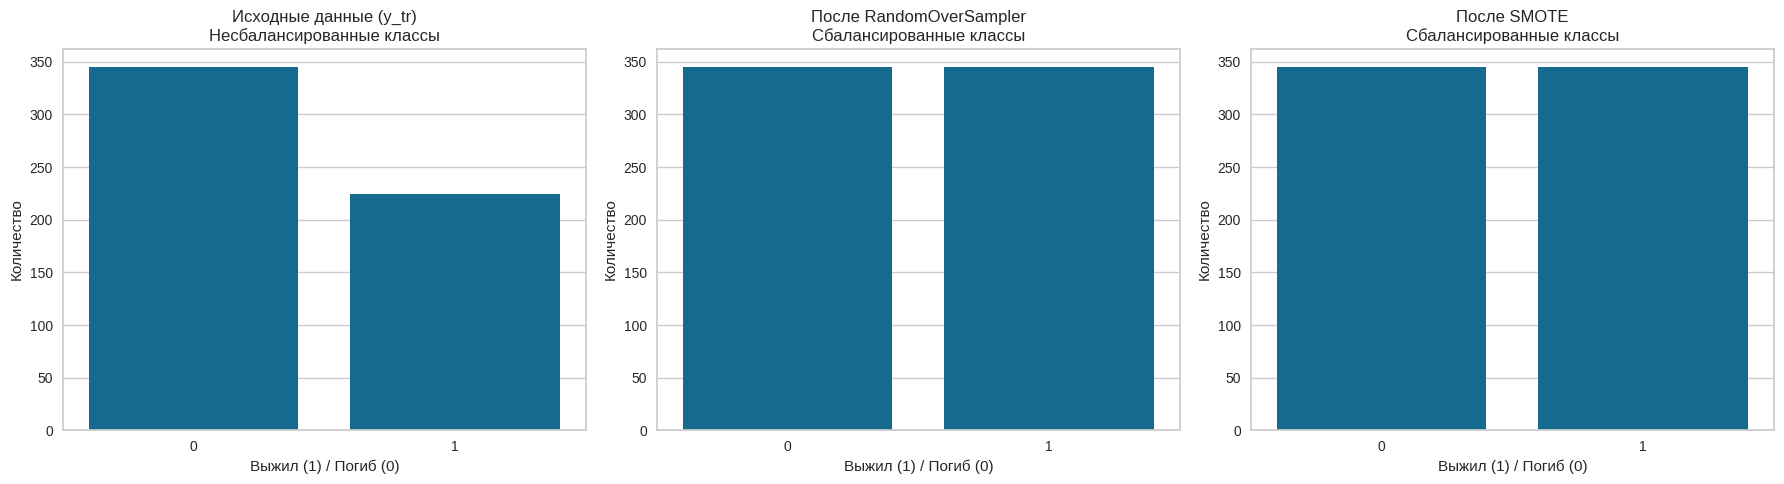

Исходные данные:
Survived
0    345
1    224
Name: count, dtype: int64

После RandomOverSampler:
Survived
0    345
1    345
Name: count, dtype: int64

После SMOTE:
Survived
0    345
1    345
Name: count, dtype: int64


In [13]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
sex = pd.get_dummies(training_set['Sex'], drop_first=True)
embark = pd.get_dummies(training_set['Embarked'], drop_first=True)
training_set = pd.concat([training_set, sex, embark], axis=1)
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)
y = training_set[['Survived']]
x = training_set.drop(['Survived'],axis=1)
x_tr,x_val,y_tr,y_val = train_test_split(x,y,train_size=0.8)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Исходные данные
sns.countplot(x=y_tr['Survived'], ax=axes[0])
axes[0].set_title('Исходные данные (y_tr)\nНесбалансированные классы')
axes[0].set_xlabel('Выжил (1) / Погиб (0)')
axes[0].set_ylabel('Количество')

# RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(x_tr, y_tr)
sns.countplot(x=y_train_ros['Survived'], ax=axes[1])
axes[1].set_title('После RandomOverSampler\nСбалансированные классы')
axes[1].set_xlabel('Выжил (1) / Погиб (0)')
axes[1].set_ylabel('Количество')

# SMOTE: Создает синтетические примеры миноритарного класса, интерполируя между существующими примерами.
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(x_tr, y_tr)
sns.countplot(x=y_train_smote['Survived'], ax=axes[2])
axes[2].set_title('После SMOTE\nСбалансированные классы')
axes[2].set_xlabel('Выжил (1) / Погиб (0)')
axes[2].set_ylabel('Количество')

plt.tight_layout()
plt.show()

# Вывод численных значений
print("Исходные данные:")
print(y_tr['Survived'].value_counts())
print("\nПосле RandomOverSampler:")
print(y_train_ros['Survived'].value_counts())
print("\nПосле SMOTE:")
print(y_train_smote['Survived'].value_counts())

# 13.Удалите лишние объекты мажоритарного класса (выбранные случайно)

Text(0, 0.5, 'Количество')

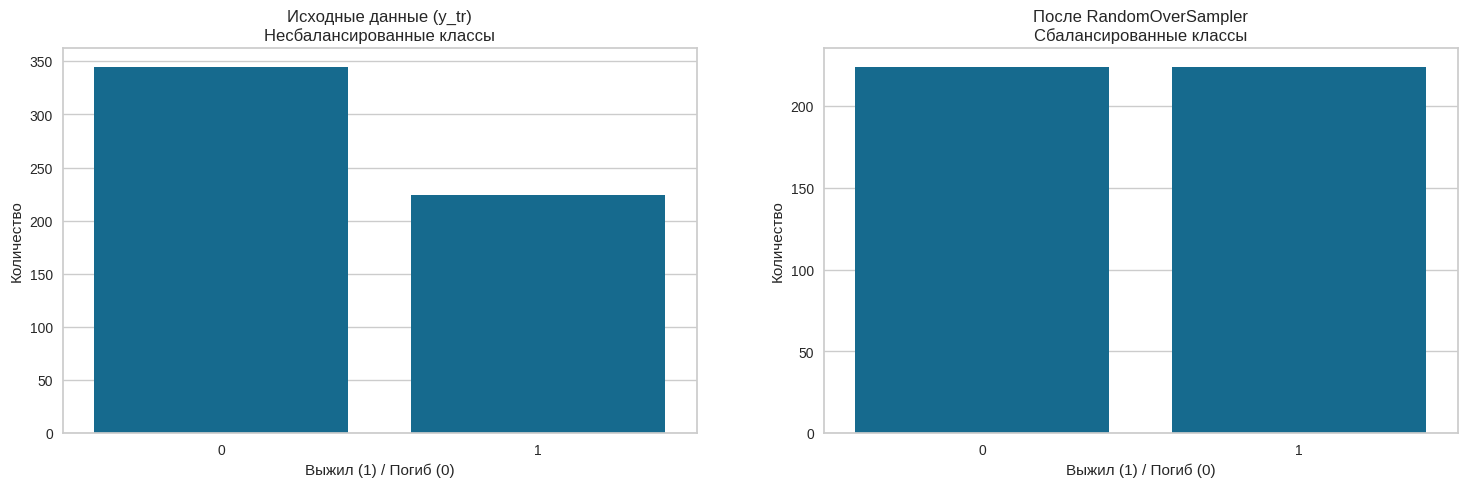

In [16]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
sex = pd.get_dummies(training_set['Sex'], drop_first=True)
embark = pd.get_dummies(training_set['Embarked'], drop_first=True)
training_set = pd.concat([training_set, sex, embark], axis=1)
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)
y = training_set[['Survived']]
x = training_set.drop(['Survived'],axis=1)
x_tr,x_val,y_tr,y_val = train_test_split(x,y,train_size=0.8)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Исходные данные
sns.countplot(x=y_tr['Survived'], ax=axes[0])
axes[0].set_title('Исходные данные (y_tr)\nНесбалансированные классы')
axes[0].set_xlabel('Выжил (1) / Погиб (0)')
axes[0].set_ylabel('Количество')

# RandomUnderSampler: Случайно удаляет примеры из мажоритарного класса, чтобы сбалансировать классы.
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(x_tr, y_tr)
sns.countplot(x=y_train_rus['Survived'], ax=axes[1])
axes[1].set_title('После RandomOverSampler\nСбалансированные классы')
axes[1].set_xlabel('Выжил (1) / Погиб (0)')
axes[1].set_ylabel('Количество')

# 14.Добавьте в выборку дубликаты миноритарного класса.

Text(0, 0.5, 'Количество')

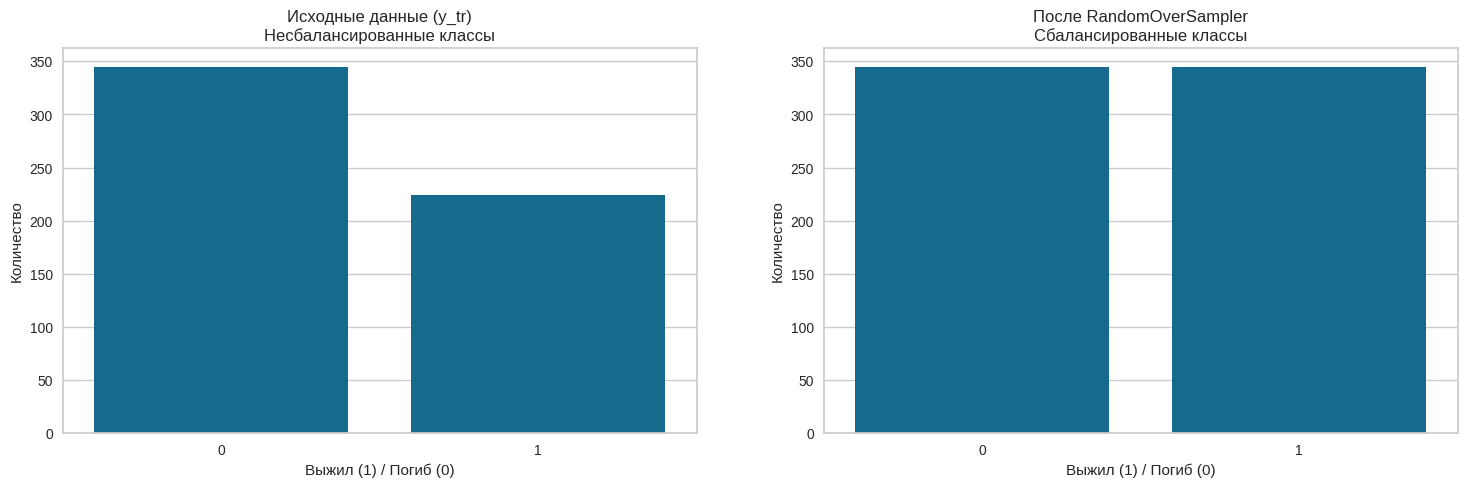

In [18]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
sex = pd.get_dummies(training_set['Sex'], drop_first=True)
embark = pd.get_dummies(training_set['Embarked'], drop_first=True)
training_set = pd.concat([training_set, sex, embark], axis=1)
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)
y = training_set[['Survived']]
x = training_set.drop(['Survived'],axis=1)
x_tr,x_val,y_tr,y_val = train_test_split(x,y,train_size=0.8)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Исходные данные
sns.countplot(x=y_tr['Survived'], ax=axes[0])
axes[0].set_title('Исходные данные (y_tr)\nНесбалансированные классы')
axes[0].set_xlabel('Выжил (1) / Погиб (0)')
axes[0].set_ylabel('Количество')

# RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(x_tr, y_tr)
sns.countplot(x=y_train_ros['Survived'], ax=axes[1])
axes[1].set_title('После RandomOverSampler\nСбалансированные классы')
axes[1].set_xlabel('Выжил (1) / Погиб (0)')
axes[1].set_ylabel('Количество')

# 15.Проведите исследование эффективности простой модели классификации до и после данных преобразований.

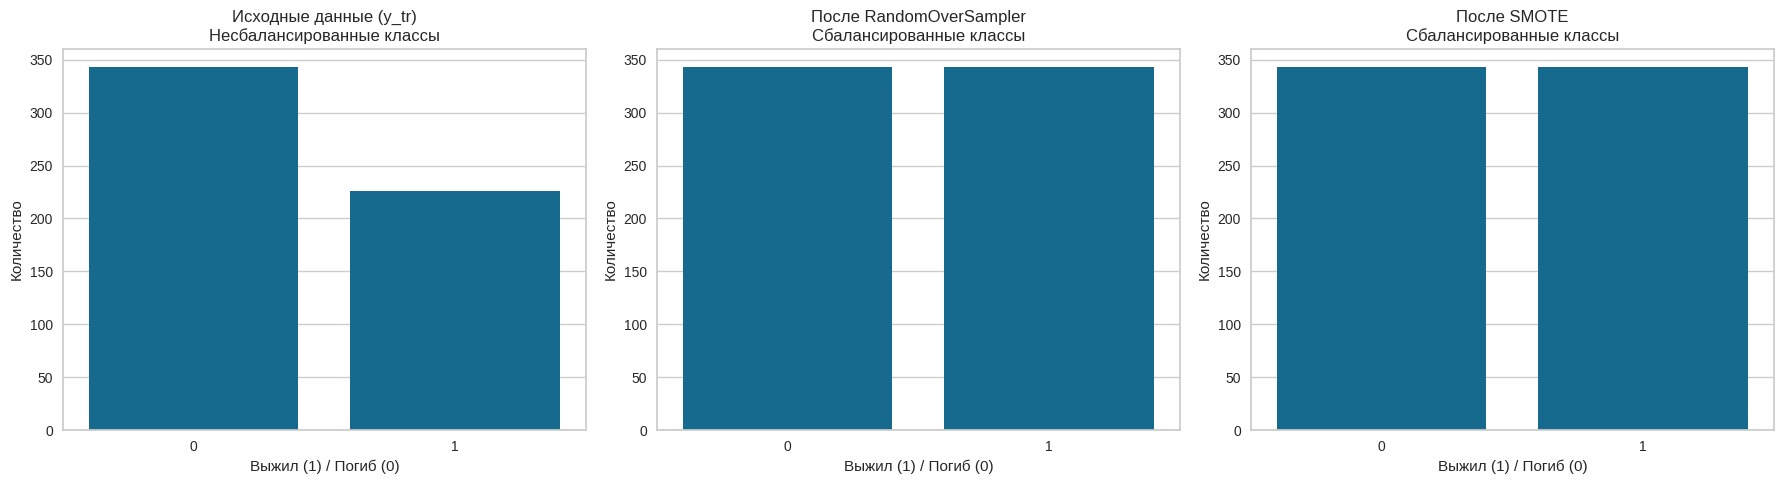

Исходные данные:
Survived
0    343
1    226
Name: count, dtype: int64
LogReg:       0.7622377622377622
DecisionTree: 0.7482517482517482

После RandomOverSampler:
Survived
1    343
0    343
Name: count, dtype: int64
LogReg:       0.7482517482517482
DecisionTree: 0.7062937062937062

После SMOTE:
Survived
1    343
0    343
Name: count, dtype: int64
LogReg:       0.7762237762237763
DecisionTree: 0.7342657342657343


In [19]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
sex = pd.get_dummies(training_set['Sex'], drop_first=True)
embark = pd.get_dummies(training_set['Embarked'], drop_first=True)
training_set = pd.concat([training_set, sex, embark], axis=1)
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)
y = training_set[['Survived']]
x = training_set.drop(['Survived'],axis=1)
x_tr,x_val,y_tr,y_val = train_test_split(x,y,train_size=0.8)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Исходные данные
sns.countplot(x=y_tr['Survived'], ax=axes[0])
axes[0].set_title('Исходные данные (y_tr)\nНесбалансированные классы')
axes[0].set_xlabel('Выжил (1) / Погиб (0)')
axes[0].set_ylabel('Количество')

# RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(x_tr, y_tr)
sns.countplot(x=y_train_ros['Survived'], ax=axes[1])
axes[1].set_title('После RandomOverSampler\nСбалансированные классы')
axes[1].set_xlabel('Выжил (1) / Погиб (0)')
axes[1].set_ylabel('Количество')

# SMOTE: Создает синтетические примеры миноритарного класса, интерполируя между существующими примерами.
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(x_tr, y_tr)
sns.countplot(x=y_train_smote['Survived'], ax=axes[2])
axes[2].set_title('После SMOTE\nСбалансированные классы')
axes[2].set_xlabel('Выжил (1) / Погиб (0)')
axes[2].set_ylabel('Количество')

plt.tight_layout()
plt.show()

print("Исходные данные:")
print(y_tr['Survived'].value_counts())
m = LR()
d = DTC()
print(f'LogReg:       {m.fit(x_tr,y_tr).score(x_val,y_val)}')
print(f'DecisionTree: {d.fit(x_tr,y_tr).score(x_val,y_val)}')
print("\nПосле RandomOverSampler:")
print(y_train_ros['Survived'].value_counts())
print(f'LogReg:       {m.fit(X_train_ros, y_train_ros).score(x_val,y_val)}')
print(f'DecisionTree: {d.fit(X_train_ros, y_train_ros).score(x_val,y_val)}')
print("\nПосле SMOTE:")
print(y_train_smote['Survived'].value_counts())
print(f'LogReg:       {m.fit(X_train_smote, y_train_smote).score(x_val,y_val)}')
print(f'DecisionTree: {d.fit(X_train_smote, y_train_smote).score(x_val,y_val)}')

# 16.Постройте корреляционную матрицу признаков после преобразования данных. Сделайте вывод о наличии либо отсутствии мультиколлинеарности признаков.

<Axes: >

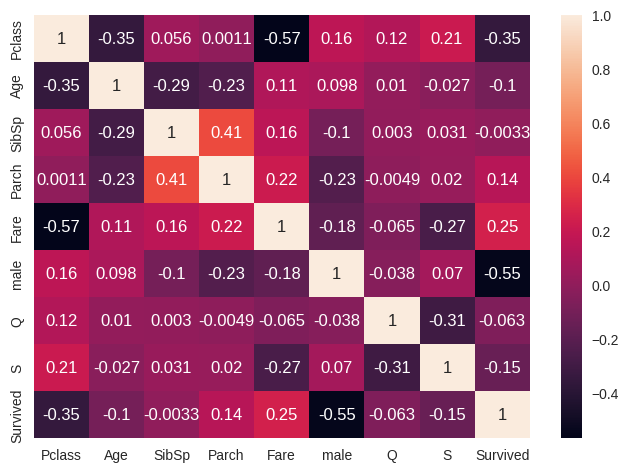

In [21]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
sex = pd.get_dummies(training_set['Sex'], drop_first=True)
embark = pd.get_dummies(training_set['Embarked'], drop_first=True)
training_set = pd.concat([training_set, sex, embark], axis=1)
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)
y = training_set[['Survived']]
x = training_set.drop(['Survived'],axis=1)
x_tr,x_val,y_tr,y_val = train_test_split(x,y,train_size=0.8)


# Применяем RandomOverSampler
X_train_ros, y_train_ros = ros.fit_resample(x_tr, y_tr)
train_ros_df = pd.concat([X_train_ros, y_train_ros], axis=1)

sns.heatmap(train_ros_df.corr(),annot=True)

# 17.Проведите группировку данных по значению возраста. Введите новый признак "возрастная категория", значениями которой будут "ребенок", "взрослый", "старик". Проведите анализ эффективности данного признака.

In [22]:
training_set.columns

Index(['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'male', 'Q',
       'S'],
      dtype='object')

In [24]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
sex = pd.get_dummies(training_set['Sex'], drop_first=True)
embark = pd.get_dummies(training_set['Embarked'], drop_first=True)
training_set = pd.concat([training_set, sex, embark], axis=1)
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)
y = training_set[['Survived']]
x = training_set.drop(['Survived'],axis=1)
x_tr,x_val,y_tr,y_val = train_test_split(x,y,train_size=0.8)


def age_category(age):
    if age < 18:
        return 'ребенок'
    elif age < 60:
        return 'взрослый'
    else:
        return 'старик'

# Добавляем новый признак
training_set['age_category'] = training_set['Age'].apply(age_category)

# Преобразуем категории в dummy-переменные
age_dummies = pd.get_dummies(training_set['age_category'], prefix='age')
training_set = pd.concat([training_set, age_dummies], axis=1)

# Подготовка данных (используем x_tr, x_val из предыдущего кода)
x_tr = training_set.loc[x_tr.index].drop(['Survived', 'age_category'], axis=1, errors='ignore')
x_val = training_set.loc[x_val.index].drop(['Survived', 'age_category'], axis=1, errors='ignore')

# Проверка эффективности
m = LR(max_iter=1000)
d = DTC()

print('Без возрастных категорий:')
print(f'LogReg:       {m.fit(x_tr.drop(age_dummies.columns, axis=1), y_tr).score(x_val.drop(age_dummies.columns, axis=1), y_val):.4f}')
print(f'DecisionTree: {d.fit(x_tr.drop(age_dummies.columns, axis=1), y_tr).score(x_val.drop(age_dummies.columns, axis=1), y_val):.4f}')

print('\nС возрастными категориями:')
print(f'LogReg:       {m.fit(x_tr, y_tr).score(x_val, y_val):.4f}')
print(f'DecisionTree: {d.fit(x_tr, y_tr).score(x_val, y_val):.4f}')

# Анализ выживаемости по категориям
print('\nПроцент выживших по возрастным категориям:')
print(training_set.groupby('age_category')['Survived'].mean().sort_values(ascending=False))

Без возрастных категорий:
LogReg:       0.7762
DecisionTree: 0.6853

С возрастными категориями:
LogReg:       0.7762
DecisionTree: 0.7203

Процент выживших по возрастным категориям:
age_category
ребенок     0.539823
взрослый    0.385017
старик      0.240000
Name: Survived, dtype: float64


# Дополнительные задания

# 1.Выдвиньте и проверьте статистические гипотезы о виде распределения атрибутов исходного набора данных.

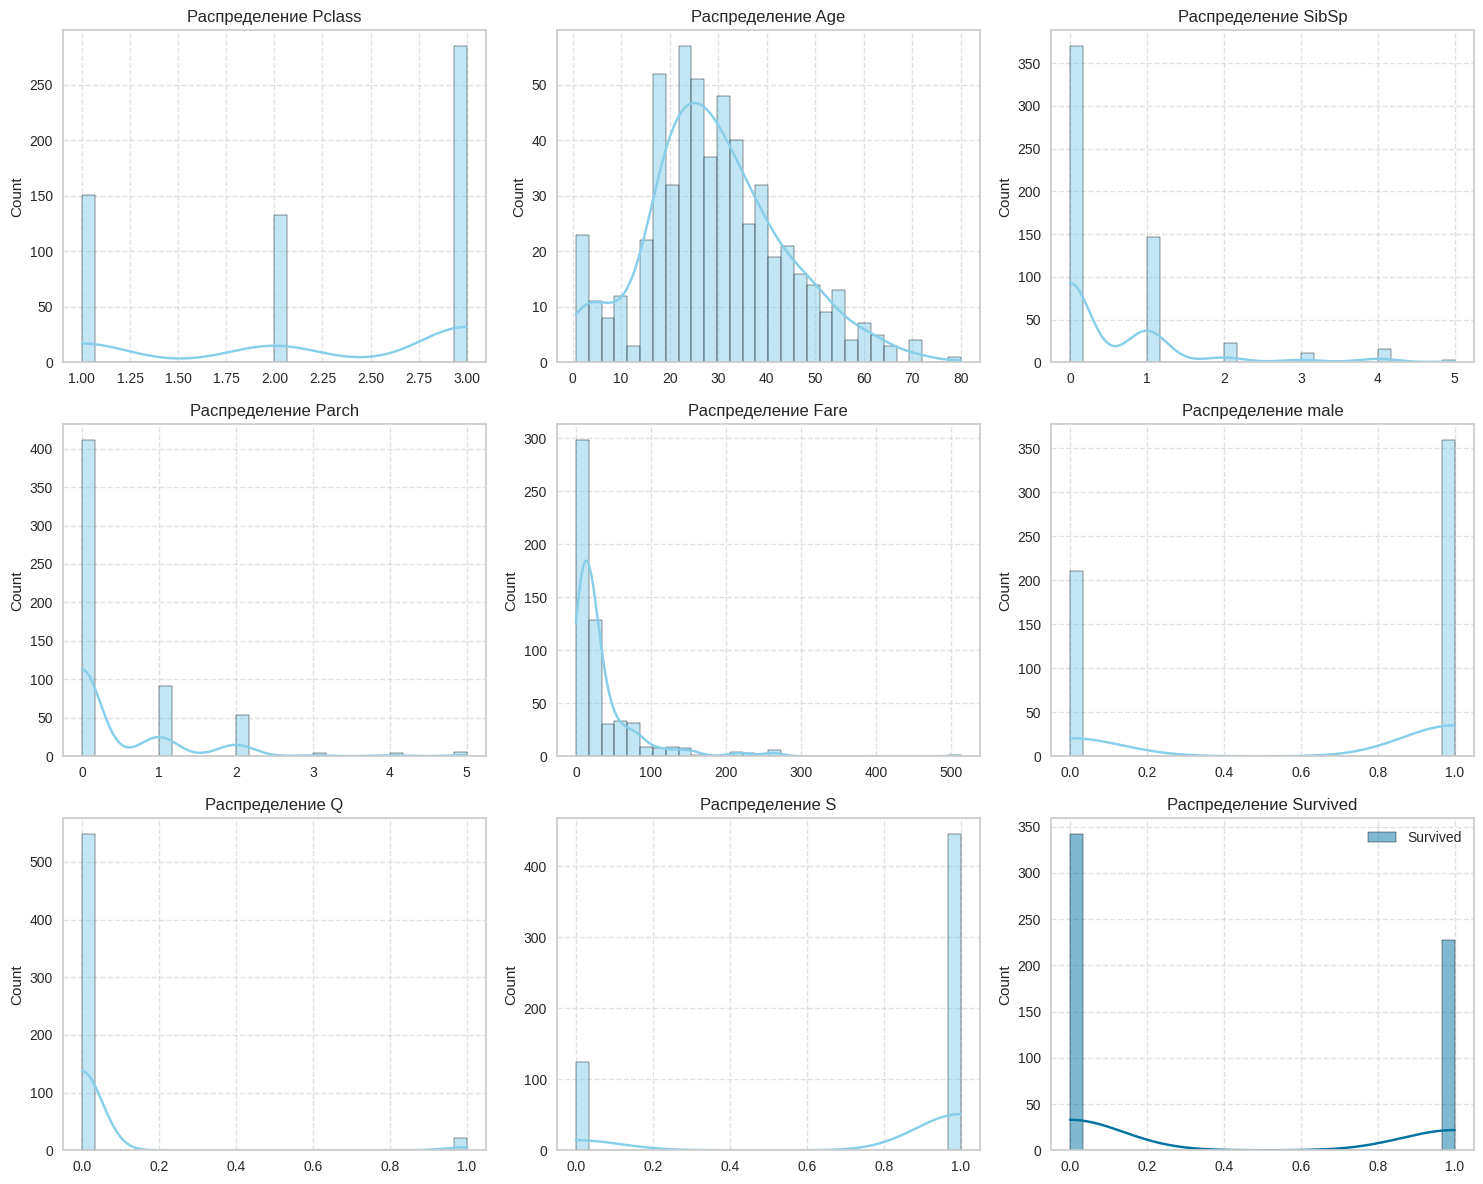

In [25]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
sex = pd.get_dummies(training_set['Sex'], drop_first=True)
embark = pd.get_dummies(training_set['Embarked'], drop_first=True)
training_set = pd.concat([training_set, sex, embark], axis=1)
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)
y = training_set[['Survived']]
x = training_set.drop(['Survived'],axis=1)

#Разделите выборку на тестовую и обучающую части при помощи train_test_split()
x_tr,x_val,y_tr,y_val = train_test_split(x,y,train_size=0.8)



#Изобразите на графиках распределение некоторых атрибутов и целевой переменной. Насколько однородно получившееся разбиение?
n_cols = 3  # Количество графиков в строке
n_rows = (len(x_tr.columns)) // n_cols + 1  # Вычисляем нужное количество строк

# Создаем полотно с subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows*4))
axes = axes.flatten()  # Преобразуем в плоский массив для удобного доступа

# Строим графики для каждого признака
for i, column in enumerate(x_tr.columns):
    # Гистограмма с KDE
    sns.histplot(x_tr[column], ax=axes[i], kde=True, bins=30, color='skyblue')
    axes[i].set_title(f'Распределение {column}')
    axes[i].set_xlabel('')
    axes[i].grid(True, linestyle='--', alpha=0.6)

# Целевая пременная
sns.histplot(y_tr, ax=axes[-1], kde=True, bins=30, color='skyblue')
axes[-1].set_title(f'Распределение {y_tr.columns[0]}')
axes[-1].set_xlabel('')
axes[-1].grid(True, linestyle='--', alpha=0.6)



plt.tight_layout()
plt.show()

# 2.Проведите автоматизированный отбор признаков тремя методами:

In [27]:
training_set = pd.read_csv('/content/titanic 5_5.csv')
training_set.drop('Cabin', axis=1, inplace=True);training_set.dropna(inplace=True);
sex = pd.get_dummies(training_set['Sex'], drop_first=True)
embark = pd.get_dummies(training_set['Embarked'], drop_first=True)
training_set = pd.concat([training_set, sex, embark], axis=1)
training_set.drop(['Sex', 'Embarked', 'Name', 'Ticket', 'PassengerId'], axis=1, inplace=True)
y = training_set[['Survived']]
x = training_set.drop(['Survived'],axis=1)
x_tr,x_val,y_tr,y_val = train_test_split(x,y,train_size=0.8)
model = LR(max_iter=1000, random_state=42)

# 3.Поочередное исключение признаков из модели. Начните с модели, включающей все признаки. Найдите признак, исключение которого приводит к наибольшему повышению эффективности модели. Затем по такому же принципу исключите второй признак, и так до тех пор, пока исключение признаков может повысить эффективность.

In [28]:
#Поочередное исключение признаков (Backward Elimination)
print("Метод 3: Поочередное исключение признаков")
current_features = list(x_tr.columns)
best_score = model.fit(x_tr[current_features], y_tr).score(x_val[current_features], y_val)
improved = True

while improved and len(current_features) > 1:
    improved = False
    worst_feature = None

    for feature in current_features:
        temp_features = [f for f in current_features if f != feature]
        score = model.fit(x_tr[temp_features], y_tr).score(x_val[temp_features], y_val)

        if score > best_score:
            best_score = score
            worst_feature = feature
            improved = True

    if improved:
        current_features.remove(worst_feature)
        print(f"Удален признак {worst_feature}, точность: {best_score:.4f}")

print(f"\nИтоговые признаки: {current_features}")
print(f"Лучшая точность: {best_score:.4f}\n")

Метод 3: Поочередное исключение признаков
Удален признак Parch, точность: 0.8322
Удален признак Fare, точность: 0.8392

Итоговые признаки: ['Pclass', 'Age', 'SibSp', 'male', 'Q', 'S']
Лучшая точность: 0.8392



# 4.Поочередное включение признаков. Начните с парной модели с наибольшей эффективностью. Найдите второй признак, включение которого в модель дает наибольший прирост эффективности. Продолжайте добавлять признаки в модель по одному пока это приводит к росту эффективности.

In [29]:
#Поочередное включение признаков (Forward Selection)
print("Метод 4: Поочередное включение признаков")
remaining_features = list(x_tr.columns)
current_features = []
best_score = 0
improved = True

while improved and remaining_features:
    improved = False
    best_feature = None

    for feature in remaining_features:
        temp_features = current_features + [feature]
        score = model.fit(x_tr[temp_features], y_tr).score(x_val[temp_features], y_val)

        if score > best_score:
            best_score = score
            best_feature = feature
            improved = True

    if improved:
        current_features.append(best_feature)
        remaining_features.remove(best_feature)
        print(f"Добавлен признак {best_feature}, точность: {best_score:.4f}")

print(f"\nИтоговые признаки: {current_features}")
print(f"Лучшая точность: {best_score:.4f}\n")


Метод 4: Поочередное включение признаков
Добавлен признак male, точность: 0.8112

Итоговые признаки: ['male']
Лучшая точность: 0.8112



# 5.Постройте вектор важности признаков. Опираясь на него включайте признаки в модель по одному в порядке уменьшения относительной важности. Найдите набор признаков, который дает наибольшую эффективность.

Метод 5: Отбор по важности признаков


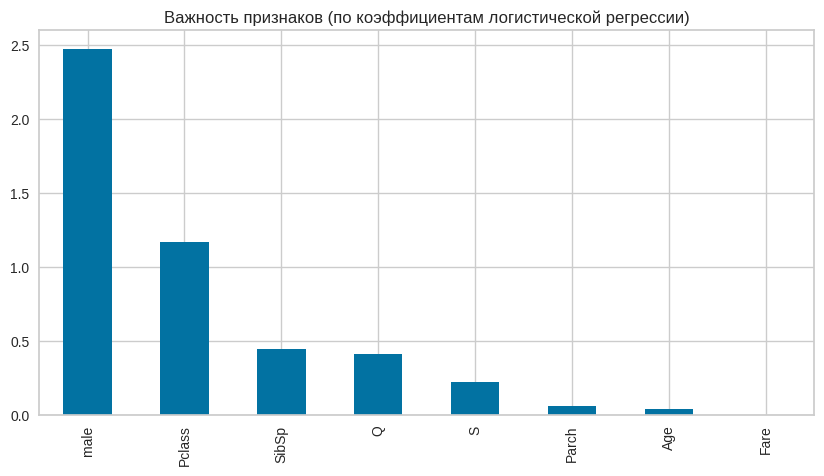

Добавлен признак male, точность: 0.8112
Добавлен признак Pclass, точность: 0.8112
Добавлен признак SibSp, точность: 0.8042
Добавлен признак Q, точность: 0.8042
Добавлен признак S, точность: 0.7972
Добавлен признак Parch, точность: 0.7972
Добавлен признак Age, точность: 0.8252
Добавлен признак Fare, точность: 0.8252

Оптимальные признаки: ['male', 'Pclass', 'SibSp', 'Q', 'S', 'Parch', 'Age']
Лучшая точность: 0.8252


In [30]:
#Отбор по важности признаков
print("Метод 5: Отбор по важности признаков")
model.fit(x_tr, y_tr)
importances = pd.Series(model.coef_[0], index=x_tr.columns).abs().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
importances.plot(kind='bar')
plt.title("Важность признаков (по коэффициентам логистической регрессии)")
plt.show()

current_features = []
best_score = 0

for feature in importances.index:
    current_features.append(feature)
    score = model.fit(x_tr[current_features], y_tr).score(x_val[current_features], y_val)
    print(f"Добавлен признак {feature}, точность: {score:.4f}")

    if score > best_score:
        best_score = score
        optimal_features = current_features.copy()

print(f"\nОптимальные признаки: {optimal_features}")
print(f"Лучшая точность: {best_score:.4f}")